In [1]:
import sys
import csv
from random import shuffle

import numpy as np
import pandas as pd
import requests
import os
from pathlib import Path
from io import StringIO
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import KFold
from torchsummary import summary

PROJECT_ROOT = Path(r'C:\Users\gitsw\Desktop\clear_desktop\TechnicalPortfolio\swetshgit\DL_CUDA_Excercise')

In [2]:
print(f'Project root: {PROJECT_ROOT}')

Project root: C:\Users\gitsw\Desktop\clear_desktop\TechnicalPortfolio\swetshgit\DL_CUDA_Excercise


In [3]:
# feature_list = [
#     'GPS Bearing(deg)',
#     'GPS Altitude(m)',
#     'O2 Lambda Current ER(ratio)',
#     'MAF(l/s)','Speed(km/h)',
#     'GPS Speed(km/h)',
#     'Rpm(u/min)',
#     'O2 Lambda Current(A)',
#     'Throttle Position(%)',
#     'Intake Pressure(kPa)',
#     'GPS Accuracy(%)',
#     'Intake Temperature(c)',
#     'Engine Load(%)',
#     'longitude',
#     'latitude'
# ]
target_value = 'CO2(kg/h)'
feature_list = [
    # 'GPS Bearing(deg)',
    # 'GPS HDOP(precision)',
    # 'GPS Altitude(m)',
    'Speed(km/h)',
    'Rpm(u/min)',
    'Consumption(l/h)',
    'Throttle Position(%)',
    'Intake Temperature(c)',
    'Engine Load(%)'
]

required_columns = [
    'id',
    'CO2(kg/h)',
    'GPS Bearing(deg)',
    'GPS HDOP(precision)',
    'GPS Altitude(m)',
    'Consumption(l/h)',
    'Speed(km/h)',
    'Rpm(u/min)',
    'Throttle Position(%)',
    'Intake Temperature(c)',
    'Engine Load(%)',
    'time'
]
download_output_dir = 'envirocar_tracks_csv'
original_delimiter = ';'

original_dataset_csv = 'original_dataset.csv'

original_dataset_features = [
'GPS_Speed_Ms','GPS_HDOP','GPS_Bearing','Gx','Gy','Gz','G_Calibrated','OBD_KPL_Average','OBD_Trip_KPL_Average','OBD_Intake_Air_Temp_C','Device_Barometer_M','GPS_Altitude_M','OBD_Engine_Load','OBD_Fuel_Level','GPS_Accuracy_M','OBD_Speed_Km','GPS_Speed_Km','Device_Trip_Dist_Km','OBD_Engine_Coolant_Temp_C','OBD_Engine_RPM','OBD_Adapter_Voltage','OBD_KPL_Instant','OBD_Fuel_Flow_CCmin','Device_Fuel_Remaining','OBD_Ambient_Air_Temp_C','OBD_CO2_gkm_Average',
    #'Device_Cost_Km_Inst',
    'Device_Cost_Km_Trip','OBD_Air_Pedal','Context','Acceleration_kmhs','Reaction_Time','Air_Drag_Force','Speed_RPM_Relation','KPL_Instant'
]
original_dataset_target = 'OBD_CO2_gkm_Instant'

output_dir = 'imputed_envirocar_data'
output_dir_2 = 'neviro_car_2'
delimiter_value = ','

# output_dir = 'envirocar_tracks_csv'
# delimiter_value = ';'

loss_image_dir = "loss_images"

all_columns_present_id_list = ['661245119828af15e2717fed', '6612450a9828af15e2717c76', '660b61e09828af15e232d0c3', '660b61da9828af15e232ce12', '65eeef0527de036499a72864', '65eeef0a27de036499a72b1b', '65ab9613769a4a5c859dbad6', '65ab9617769a4a5c859dbead', '65ab9626769a4a5c859dc49a', '65ab962a769a4a5c859dc820', '659fa485e4334e110cc91523', '65868308e4334e110cc30bc0', '6586830ce4334e110cc31030', '65868321e4334e110cc31e25', '65868325e4334e110cc32271', '657d6e21e4334e110c29a519', '657d6e27e4334e110c29a61d', '65716543e4334e110c24925a', '655efd4de4334e110cefdb1c', '655efd53e4334e110cefddca', '6520ed349186d0330638b754', '6520ed2f9186d0330638b4ac', '64fc075ade656f7b9eefe24f', '64fc075ade656f7b9eefe364',
                               '64fc0aebde656f7b9ef01ce2', '64b1008ac7e42807e7eabb2f', '64b10090c7e42807e7eabeb2', '649e5fc6c7e42807e751c2ff', '649e5fcac7e42807e751c64f', '64952e3cc7e42807e74b6939', '64952e41c7e42807e74b71d5', '648acd0ac7e42807e7038f32', '6482e20eca0a730aef0f3c67', '6481cd86ca0a730aefddb8f3', '64725ad0ca0a730aef50ed59', '646dc14dca0a730aef443b5f', '646dc174ca0a730aef445de9', '645f34ccca0a730aef36fad2', '645f34cfca0a730aef36fdb6', '644eb8cfca0a730aef197857', '644eb8d1ca0a730aef197b89', '642e5ebcca0a730aeffd3e7a', '642e5ebfca0a730aeffd4239', '642e5ec5ca0a730aeffd4672', '642e5ec8ca0a730aeffd46e3', '642e5ed7ca0a730aeffd53f5', '642e5edaca0a730aeffd54f6', '6412b1f05244bc763ca7d46d',
                               '6412b1f45244bc763ca7d868', '6412b2105244bc763ca7f447', '6412b2145244bc763ca7fb00', '6412b2195244bc763ca7ffdc', '64051f7d5244bc763c94a2fc', '64051f875244bc763c94af3f', '64051fca5244bc763c94e69f', '64077ad15244bc763c98acd2', '64077afa5244bc763c98cdd9', '64077b235244bc763c98d0f6', '64077b265244bc763c98d341', '64077b3f5244bc763c98e4ac', '64077b425244bc763c98e652', '64077b8d5244bc763c98f6a4', '64077b915244bc763c98fca6', '64077b9c5244bc763c990c5a', '64077ba35244bc763c99114a', '64077ba75244bc763c991740', '64077f055244bc763c99491e', '64077f085244bc763c994bb1', '64077f0c5244bc763c99511a', '640782125244bc763c99ade9', '651519169186d03306fb5057', '63a40768ad53a0015a4fe31d',
                               '63a4076bad53a0015a4fe663', '63949b6ead53a0015a096c91', '63948c5cad53a0015a08e2d8', '63948c57ad53a0015a08df35', '63948c1dad53a0015a08b5a1', '63948c1aad53a0015a08b34b', '63948c0aad53a0015a08a51c', '63948c03ad53a0015a08a1e2', '63948bffad53a0015a089f29', '63948b7cad53a0015a084327', '63948b78ad53a0015a084092', '63948aa3ad53a0015a079ee0', '63948925ad53a0015a071369', '63948921ad53a0015a070f6f', '6394891aad53a0015a070a21', '63948917ad53a0015a0706d5', '6394889ead53a0015a06afda', '6394889aad53a0015a06a962', '6394888fad53a0015a0692be', '62ad78db842171051aef8304', '629d9b11842171051acb48e8', '62932392842171051abbeead', '651519f69186d03306fb65d6', '6293239f842171051abbf23e',
                               '629323a7842171051abbf458', '62907ee5842171051ab80ab9', '62907ebf842171051ab7ff00', '62907eef842171051ab821ce', '628542a5842171051acbe8a8', '628542b6842171051acc0024', '628542a4842171051acbe33d', '628542a3842171051acbdf43', '6286a087842171051ace9dd9', '6286a093842171051ace9ff6', '607a2e173b14785a90ce8429', '607a2e1b3b14785a90ce885f', '5eec7aa7d6e3cf256ba3eff9', '5eb7582165b80c5d6be69f22', '5eb7582165b80c5d6be6a142', '5e8b930a65b80c5d6b4d7f2b', '5e42ccb63965f3689459b871', '5e24ca2463c90936dc7b2d94', '5e5e5ecd77e02d42aa94ee1c', '5e1eceab1126d80318bf9f7f', '5e10ec059115b85a123190d0', '5e10ec089115b85a12319686', '5e10ec059115b85a12318e62', '5e08bc845bc8db428964203d',
                               '5e08bc7b5bc8db428964101b', '5e08bc7a5bc8db4289640c77', '5e08bc795bc8db4289640945', '5e08bc795bc8db42896409d5', '5e08bc775bc8db42896406d8', '5e08bc785bc8db4289640875', '5e08bc775bc8db428964066d', '5e6256b977e02d42aa99f3fc', '5de9d7a03bdb691868e76540', '5de0cebf44ea85025c044a15', '5de0cebf44ea85025c044aed', '5ddfd2ba44ea85025c02d828', '5ddfd2bc44ea85025c02dbce', '5de9d7a63bdb691868e77e35', '5de9d7a03bdb691868e765cd', '5ddcdd4a44ea85025cfdf878', '5ddbc67f44ea85025cfc4c10', '5dda4b8144ea856b70e667f0', '5dd7afa244ea856b70e29ecc', '5dd7afa244ea856b70e29e44', '5dd7a23e44ea856b70e28a22', '5dd68af544ea856b70e1471a', '5dd68af244ea856b70e14259', '5dd68aef44ea856b70e140fc',
                               '5dd68aed44ea856b70e13eb5', '5dd68ae944ea856b70e1382b', '5dd68ae544ea856b70e1356b', '5dc985eb44ea856b702dd8c0', '5dc9864c44ea856b702e048a', '5dc986e844ea856b702e3cb5', '5dc9879b44ea856b702e872d', '5dc9c2fe44ea856b7034cbb4', '5dca980744ea856b70363f64', '5dca9b6b44ea856b70364378', '5dcab52c44ea856b70365911', '5dcab5f044ea856b70365f6a', '5dcad90f44ea856b703681ea', '5dcad8d944ea856b70367f91', '5dcad83844ea856b70367d81', '5dcead5644ea856b704d8882', '5dcead4644ea856b704d8428', '5dcbbb1444ea856b7037b264', '5dcead4044ea856b704d8037', '5dcbbb0d44ea856b7037ae6e', '5dcbbb0244ea856b7037ab04', '5dcbb93044ea856b7037a58a', '5dca8b0244ea856b7036389b', '5dca7dce44ea856b70362ef8',
                               '5dcad99b44ea856b70368833', '5dcad96444ea856b70368445', '5dca7e7c44ea856b70363072', '5d757dff44ea853f9f7f62aa', '5d757df644ea853f9f7f6174', '5d746ed344ea853f9f7e5075', '5d5c42ab44ea8550236462ea', '5d59ad7044ea855023610e7e', '5d59ad5b44ea8550236107e0', '5d51f49844ea85502359591b', '5d51f49444ea855023595716', '5d51f48544ea855023594ea6', '5d336ae244ea855023d3745e', '5d336ade44ea855023d372d7', '5d222f4644ea855023c1d0c0', '5d222f2844ea855023c1c8f0', '5d222f2244ea855023c1c7f9', '5d15eef544ea855023b4456f', '5ced330544ea850302918bec', '5ced358044ea850302922200', '5ced359f44ea8503029222ae', '5c95155944ea850302f58228', '5c8c120944ea85030266906a', '5c8c1cc244ea850302669b50',
                               '5c718e9844ea85030245e824', '5c6dba6c44ea85030209b9ae', '5c6dc37c44ea85030209bbc1', '5c684aea44ea850302048409', '5c6844a544ea85030204806f', '5c60075444ea850302fbddf7', '5c5edd0c44ea850302fa9dcd', '5c5edd2744ea850302faa614', '5c28ccc244ea850302c4fd98', '5c28f94644ea850302c50153', '5c26511444ea850302c2d5bf', '5c263bbc44ea850302c2d2b9', '5c0971e344ea8503029b8a83', '5c096abd44ea8503029afd17', '5bfa55dd44ea8503028f0d2e', '5bf9162d44ea8503028df2cf', '5bf90edc44ea8503028df1b2', '5bf8376a44ea8503028ce7af', '5bf831d144ea8503028ce6ee', '5ba9ecf344ea8508426dd940', '5b8847bf44ea8508429306f9', '5b88441b44ea850842930670', '5b76e4f844ea8508423c57d2', '5b74809e44ea8508423177f4',
                               '5b6dd5c644ea85084220335f', '5b6dd3a144ea8508421ffe91', '5b27e0d644ea85091053c8cb', '5b27a84844ea85091053b86f', '5b1cfe7544ea8508ccf04471', '5b1cf8fa44ea8508ccf03cfc', '5ad2479644ea8508c543f14b', '5ad2114844ea8508c543bce1', '5acf80fb44ea8508c53e3cb4', '5a981a8944ea851012d70797', '5a98156544ea851012d68d18', '5a89ceae44ea851012bcc8f5', '5a89cbba44ea851012bcbee4', '5a7f8ea244ea851012b1cae2', '5a7f843d44ea851012b1ca88', '5a7f82d244ea851012b1c4ae', '5a7f564f44ea851012b1b9e7', '5a7f4d4a44ea851012b1b247', '5a625b5a44ea8508ffa54197', '5a61c09544ea85087e7a8d86', '5a61c09344ea85087e7a8bf3', '5a61ae2044ea85087e7a82df', '5a60e7b044ea85087e7a7344', '5a5a5bc944ea85087e6bf7b3',
                               '5a34130f44ea8513da639e87', '5a3412fb44ea8513da639d87', '5a2c14ed268d1b08cd0c27ec', '5a2c14ea268d1b08cd0c1e79', '59cd1eb9268d1b086009a72e', '593165ec268d1b08a4ac122b', '59316592268d1b08a4abfaaa', '59316529268d1b08a4abe33c', '59316569268d1b08a4abee8e', '59249f41268d1b08a49e0507', '59249f30268d1b08a49dfae5', '5915c1f0268d1b08a48d36b2', '5915c1b3268d1b08a48d2a28', '5914078d268d1b08a48bc5fb', '59033b83268d1b08a46be37a', '59033b7b268d1b08a46bd92c', '585198a2e4b0a979d5571317', '5851871de4b0a979d5571212', '57813841e4b0ea2464510f5e', '5760009ee4b091b7fc69d5ca', '5760009ce4b091b7fc69d377', '575bca4ae4b0a69192a28d73', '575bca49e4b0a69192a28be9', '575b17d3e4b0a69192a213b2',
                               '575a63bbe4b0a691929d1f30', '575a63b5e4b0a691929d1c92', '57593b13e4b0a6919296818f', '575860c3e4b0a6919294351a', '575826c1e4b0a6919292205e', '575826bfe4b0a69192921ec8', '5755a4a7e4b0a691928224f9', '57553109e4b0a691927df43a', '573aba1ce4b09078f96804c0', '57337c7fe4b09078f961f02b', '5705764ee4b0b5e237edae2a', '5705764be4b0b5e237edac7f', '57057648e4b0b5e237edab37', '56f120ede4b0b5e237d5756f', '56ee65abe4b0b5e237d32e7f', '56c4766fe4b0df8fa0524f2f', '56c22080e4b0df8fa05006da', '56bbae8ce4b0df8fa021e387', '56bbae8ae4b0df8fa021e284', '56b4dd7de4b0df8fa00669aa', '56b464a2e4b0df8fa005c794', '56b326c0e4b0df8fa0058105', '56b318e8e4b0df8fa0057d11', '56b3170de4b0df8fa0057314',
                               '56b21cede4b0df8fa004baee', '56b21ceae4b0df8fa004b85c', '56af2fb6e4b058e54940a0c2', '56af2fb3e4b058e54940a022', '56a87695e4b000f94dbbc0d5', '56a781bbe4b000f94dbb91d0', '569635d6e4b000f94da7ff63', '569635d1e4b000f94da7fc7c', '567aa2cfe4b000f94d91c837', '567aa2a8e4b000f94d91c72d', '554ce07de4b048885ee0dfa7', '552bff35e4b0bf5f3e46d683', '552bff31e4b0bf5f3e46d3fc', '552418ace4b0bf5f3e43d3ad', '55241876e4b0bf5f3e43a4aa', '553aa4b9e4b080c763779442', '553aa525e4b080c76377a19d', '553aa4b2e4b080c76377917f', '553aa4e9e4b080c763779eda', '55080c87e4b0bf5f3d061b07', '55080c7ee4b0bf5f3d061868', '55241838e4b0bf5f3e437753', '54fda58ae4b0bf5f3cf0d400', '54fda589e4b0bf5f3cf0d0f9',
                               '54fc4853e4b0bf5f3ceb0ad3', '54fc484de4b0bf5f3ceb097c', '54fda585e4b0bf5f3cf0ce0a', '54e30adbe4b0558690c54e8e', '54ec23d6e4b0558690c83df7', '54ec2575e4b0558690c894b3', '54ec2ad2e4b0558690c8e968', '54ec2f1ee4b0558690c939fa', '54ec3350e4b0558690c9809a', '54ec23d1e4b0558690c83b00', '54ec256fe4b0558690c891bc', '54ec2acce4b0558690c8e671', '54ec2f18e4b0558690c93703', '54e30acce4b0558690c54ba8', '54e30a82e4b0558690c54556', '54706aa8e4b094c1030086ea', '53b514bee4b01607fa560ce2', '53b3b0dee4b01607fa556250', '53b3b0f8e4b01607fa5591f5', '53b3b0d6e4b01607fa554637', '53b3b0f0e4b01607fa558784', '53b3b0cde4b01607fa552940', '53b3b0e8e4b01607fa5575d5', '53b3b066e4b01607fa54ed80',
                               '53b2cda1e4b01607fa5454e1', '53b2cd91e4b01607fa544f12', '53b2cd7de4b01607fa544927', '53b2cd6ae4b01607fa54417c', '53b27494e4b01607fa538d1d', '53b5228ee4b01607fa566b78', '53b52282e4b01607fa566469', '53b27449e4b01607fa53736d', '53b52277e4b01607fa565fa6', '53b52266e4b01607fa5656d3', '5371e972e4b05e62155002c4', '5371e96ce4b05e62154ff5ad', '535e0898e4b0976b09bda467', '535e0896e4b0976b09bda210', '5357a002e4b0976b09b935d0', '53579ffce4b0976b09b91b09', '53218b43e4b0c917fe59aa8f', '52f6c62de4b0d8e8c28df6a2', '52eabd02e4b0d8e8c250ca6d', '52e39b02e4b0d8e8c22665c3', '52caf543e4b0f9afbd8d7f8c', '52b19f7ce4b0f9afbd14d773', '52b19f7ae4b0f9afbd14d3a0', '52af4fe9e4b0593cce13cf5d',
                               '52af4fe4e4b0593cce13ccc6', '52af4fe1e4b0593cce13cc37', '528f1a19e4b0ca505ba93418', '528f1a23e4b0ca505ba943d3', '528f1a16e4b0ca505ba92f41', '528f1a20e4b0ca505ba93efc', '52af4fd3e4b0593cce13bfc7', '52af4fd0e4b0593cce13bebc', '528bd8b1e4b08cecc5a6f8bc', '528349ade4b08cecc5a0a0b8', '528349bee4b08cecc5a0b98d']
print("len", len(all_columns_present_id_list))

len 371


In [4]:
imputation_methods = {
    'CO2(kg/h)': 'mean',
    'GPS HDOP(precision)': 'ffill',
    'GPS Altitude(m)': 'ffill',
    'GPS Bearing(deg)': 'ffill',
    'Consumption(l/h)': 'mean',
    'Speed(km/h)': 'mean',
    'GPS Speed(km/h)': 'ffill',
    'Rpm(u/min)': 'ffill',
    'Throttle Position(%)':'mean',
    'GPS VDOP(precision)':'ffill',
    'GPS Accuracy(%)': 'ffill',
    'GPS PDOP(precision)': 'ffill',
    'Intake Temperature(c)': 'mean',
    'Engine Load(%)': 'mean',
    'MAF(l/s)': 'mean',
}
def fill_data(df):
  for column in df.columns:
    if column in imputation_methods:
        imputation_method = imputation_methods[column]
        if imputation_method == 'mean':
            df[column] = df[column].fillna(df[column].mean())
        elif imputation_method == 'ffill':
            df[column] = df[column].ffill()

  #filling in remaining NaNs
  return df.bfill()

In [5]:
!pwd

'pwd' is not recognized as an internal or external command,
operable program or batch file.


In [6]:
print(PROJECT_ROOT / 'track_df.csv')

C:\Users\gitsw\Desktop\clear_desktop\TechnicalPortfolio\swetshgit\DL_CUDA_Excercise\track_df.csv


In [7]:
global_track_df_object = None
sequence_len = 10
ids_list = []
def set_trackdf():
    csv_path = PROJECT_ROOT / 'track_df.csv'
    if not csv_path.is_file():
        raise FileNotFoundError(f'Track metadata not found: {csv_path}')
    track_df = pd.read_csv(csv_path, low_memory=False)
    global global_track_df_object
    global_track_df_object = track_df
def get_track_ids():
    track_df = global_track_df_object
    unique_ids = track_df['track.id'].unique()
    return unique_ids

In [8]:
import time
import sys
import numpy as np
import torch
from random import shuffle

try:
    from cuda_kernels.temporal_features_wrapper import create_sequences_cuda, _CUDA_AVAILABLE
    print("[CUDA Wrapper] wrapper loaded. Compiled CUDA extension available:", _CUDA_AVAILABLE)
except Exception as e:
    _CUDA_AVAILABLE = False
    create_sequences_cuda = None
    print("[CUDA Wrapper] Compiled CUDA extension not found. Falling back to pure Python.")

def divide_track_ids():
    unique_ids = all_columns_present_id_list
    shuffle(unique_ids)
    total = len(unique_ids)
    print("total unique", total)
    train = int(0.8 * total)
    train_ids = unique_ids[:train]
    test_ids = unique_ids[train:]
    return train_ids, test_ids

def divide_sequences(X, Y):
    n = X.shape[0]
    indices = torch.randperm(n)
    shuffled_X = X[indices]
    shuffled_Y = Y[indices]

    train_split = int(0.8 * n)
    validate_split = int(0.1 * n)
    test_split = n - train_split - validate_split

    train_X = shuffled_X[:train_split]
    train_Y = shuffled_Y[:train_split]

    validate_X = shuffled_X[train_split: train_split + validate_split]
    validate_Y = shuffled_Y[train_split: train_split + validate_split]

    test_X = shuffled_X[train_split + validate_split:]
    test_Y = shuffled_Y[train_split + validate_split:]

    return (train_X, train_Y), (test_X, test_Y), (validate_X, validate_Y)

def divide_sequences_cf(X, Y):
    n = X.shape[0]
    indices = torch.randperm(n)
    shuffled_X = X[indices]
    shuffled_Y = Y[indices]

    train_split = int(0.9 * n)
    test_split = int(0.1 * n)

    train_X = shuffled_X[:train_split]
    train_Y = shuffled_Y[:train_split]

    test_X = shuffled_X[train_split:]
    test_Y = shuffled_Y[train_split:]

    return (train_X, train_Y), (test_X, test_Y)

def create_sequences_python(data, target=target_value, features=feature_list, sequence_length=60):
    """CPU baseline loop with pandas .iloc"""
    X, y = [], []
    total = len(data)
    for i in range(sequence_length, total):
        X.append(data[features].iloc[i-sequence_length:i].values)
        y.append(data[target].iloc[i])
    return torch.tensor(np.array(X), dtype=torch.float32), torch.tensor(np.array(y), dtype=torch.float32)

def create_sequences_gpu_unaccelerated(data, target=target_value, features=feature_list, sequence_length=60):
    """Create sequences on GPU with standard PyTorch indexing."""
    feature_tensor = torch.as_tensor(data[features].to_numpy(dtype=np.float32), device='cuda')
    target_tensor = torch.as_tensor(data[target].to_numpy(dtype=np.float32), device='cuda')
    row_indices = torch.arange(sequence_length, len(data), device='cuda')
    window_offsets = torch.arange(sequence_length, device='cuda')
    sequence_indices = row_indices[:, None] - sequence_length + window_offsets[None, :]
    sequences = feature_tensor[sequence_indices]
    targets = target_tensor[row_indices]
    torch.cuda.synchronize()
    return sequences.cpu(), targets.cpu()

def create_sequences(data, target=target_value, features=feature_list, sequence_length=60, use_cuda=True):
    """Creates sequences using custom CUDA Kernel if available; otherwise falls back to CPU"""
    if use_cuda and _CUDA_AVAILABLE and torch.cuda.is_available():
        return create_sequences_cuda(data, target=target, features=features, seq_len=sequence_length, device='cuda')
    return create_sequences_python(data, target=target, features=features, sequence_length=sequence_length)

def simple_hash_for_fuel_type(fuelType):
    return hash(fuelType) % 10


[CUDA Wrapper] wrapper loaded. Compiled CUDA extension available: True


In [9]:
def read_data(ids, normalised=False, original=False, use_cuda=True, benchmark=False):
    """
    Reads tracks, preprocessed with CPU or CUDA kernel, and records timing metrics.
    """
    track_df = global_track_df_object
    excluded_columns = ['id', 'time', 'track.begin', 'track.end']
    track_df = track_df.drop(columns=excluded_columns, errors='ignore')
    X = []
    y = []
    total_count = 0
    big_df = []

    total_cpu_time_ms = 0.0
    total_gpu_unaccelerated_time_ms = 0.0
    total_cuda_time_ms = 0.0
    gpu_available = use_cuda and torch.cuda.is_available()
    cuda_available = gpu_available and _CUDA_AVAILABLE

    data_dir = PROJECT_ROOT / output_dir
    if not data_dir.is_dir():
        raise FileNotFoundError(f'Data directory not found: {data_dir}')
    missing_files = []

    for track_id in ids:
        csv_file = data_dir / f'{track_id}.csv'
        if not csv_file.is_file():
            missing_files.append(csv_file.name)
            continue
        df = pd.read_csv(csv_file, delimiter=delimiter_value)
        df['time'] = pd.to_datetime(df['time'])
        df[target_value] = df[target_value].ffill()
        numerical_cols = df.select_dtypes(include='number').columns
        df[numerical_cols] = df[numerical_cols].fillna(df[numerical_cols].mean())
        df = fill_data(df)
        sequence_length = 60
        if len(df) <= sequence_length:
            print(f"Skipping track {track_id}: length {len(df)} is <= sequence length {sequence_length}")
            continue
        model_columns = feature_list + [target_value]
        missing_counts = df[model_columns].isna().sum()
        if missing_counts.any():
            missing = missing_counts[missing_counts > 0].to_dict()
            raise ValueError(f'Track {track_id} still contains missing model values: {missing}')
        if not np.isfinite(df[model_columns].to_numpy(dtype=np.float32)).all():
            raise ValueError(f'Track {track_id} contains infinite model values')
        big_df.append(df)
        total_count += len(df)

        if benchmark:
            # Measure CPU time
            t0 = time.perf_counter()
            seq_x_cpu, seq_y_cpu = create_sequences_python(df, target=target_value, features=feature_list, sequence_length=60)
            t_cpu = (time.perf_counter() - t0) * 1000
            total_cpu_time_ms += t_cpu

            if gpu_available:
                t1 = time.perf_counter()
                seq_x_gpu, seq_y_gpu = create_sequences_gpu_unaccelerated(df, target=target_value, features=feature_list, sequence_length=60)
                total_gpu_unaccelerated_time_ms += (time.perf_counter() - t1) * 1000
                if cuda_available:
                    t2 = time.perf_counter()
                    seq_x_cuda, seq_y_cuda = create_sequences(df, target=target_value, features=feature_list, sequence_length=60, use_cuda=True)
                    torch.cuda.synchronize()
                    total_cuda_time_ms += (time.perf_counter() - t2) * 1000
                    seq_x, seq_y = seq_x_cuda, seq_y_cuda
                else:
                    seq_x, seq_y = seq_x_gpu, seq_y_gpu
            else:
                seq_x, seq_y = seq_x_cpu, seq_y_cpu
        else:
            t_start = time.perf_counter()
            seq_x, seq_y = create_sequences(df, target=target_value, features=feature_list, sequence_length=60, use_cuda=cuda_available)
            if cuda_available:
                torch.cuda.synchronize()
            t_elapsed = (time.perf_counter() - t_start) * 1000
            if cuda_available:
                total_cuda_time_ms += t_elapsed
            else:
                total_cpu_time_ms += t_elapsed

        X.append(seq_x)
        y.append(seq_y)

    if not X:
        raise FileNotFoundError(
            f'No requested track CSV files were found in {data_dir}. '
            f'Missing files: {len(missing_files)}'
        )
    print("shapes", len(X), len(y), X[0].shape, y[0].shape)
    single_df = pd.concat(big_df)
    big_X = torch.cat(X)
    big_y = torch.cat(y).unsqueeze(1)
    if not torch.isfinite(big_X).all() or not torch.isfinite(big_y).all():
        raise ValueError('Non-finite values detected before normalization')

    if benchmark:
        if gpu_available:
            custom_cuda_text = f" | Custom CUDA: {total_cuda_time_ms:.1f} ms" if cuda_available else " | Custom CUDA: unavailable"
            print(f"[Preprocessing Benchmark] CPU: {total_cpu_time_ms:.1f} ms | Unaccelerated GPU: {total_gpu_unaccelerated_time_ms:.1f} ms{custom_cuda_text}")
        else:
            print(f"[Preprocessing Benchmark] CPU: {total_cpu_time_ms:.1f} ms | GPU unavailable")

    if not normalised:
        return (big_X, big_y, single_df, total_cpu_time_ms, total_gpu_unaccelerated_time_ms, total_cuda_time_ms) if benchmark else (big_X, big_y, single_df)
    else:
        min_vals_X = big_X.min(dim=0, keepdim=True)[0].min(dim=1, keepdim=True)[0]
        max_vals_X = big_X.max(dim=0, keepdim=True)[0].max(dim=1, keepdim=True)[0]
        min_vals_y = big_y.min(dim=0, keepdim=True)[0]
        max_vals_y = big_y.max(dim=0, keepdim=True)[0]
        normalized_X = (big_X - min_vals_X) / (max_vals_X - min_vals_X + 1e-8)
        normalized_y = (big_y - min_vals_y) / (max_vals_y - min_vals_y + 1e-8)
        return (normalized_X, normalized_y, single_df, total_cpu_time_ms, total_gpu_unaccelerated_time_ms, total_cuda_time_ms) if benchmark else (normalized_X, normalized_y, single_df)

def get_columns(df):
    columns = []
    datatype = []
    for column in df:
        columns.append(column)
        datatype.append(df[column].dtype)
    return columns, datatype

def check_columns(df, required_columns):
    return set(required_columns).issubset(df.columns)


In [10]:
import datetime
import matplotlib.pyplot as plt
import numpy as np

def plot_loss(train_losses, val_losses, model_name="GRU"):
    now = datetime.datetime.now()
    timestamp_string = now.strftime("%Y-%m-%d %H:%M:%S")
    plt.figure(figsize=(10, 5))
    plt.plot(train_losses, label='Training loss')
    plt.plot(val_losses, label='Validation loss')
    plt.title(f'{model_name} Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_acc(train_accuracies, valid_accuracies, model_name="GRU"):
    now = datetime.datetime.now()
    timestamp_string = now.strftime("%Y-%m-%d %H:%M:%S")
    plt.figure(figsize=(10, 5))
    plt.plot(train_accuracies, label='Training Accuracy')
    plt.plot(valid_accuracies, label='Validation Accuracy')
    plt.title(f'{model_name} Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_pred(pred, true):
    pred = pred.squeeze()
    true = true.squeeze()
    plt.plot(pred[-200:], "-o", color="r", label="Predictions", markersize=2)
    plt.plot(true[-200:], color="b", label="Actual")
    plt.ylabel("Energy Consumption (MW)")
    plt.title("Energy Consumption Prediction")
    plt.legend()
    plt.show()

def plot_cuda_comparison_dashboard(cpu_prep_ms, gpu_unaccelerated_prep_ms, cuda_prep_ms, model, model_name="GRU"):
    """
    Visualizes the acceleration comparison:
      1. Preprocessing Speedup (CPU loop vs Unaccelerated GPU vs Custom CUDA Kernel)
      2. Per-Epoch Training and Validation Latencies
      3. Training & Validation Loss Convergence
    """
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    speedup = cpu_prep_ms / max(cuda_prep_ms, 1e-4)

    # Panel 1: Preprocessing Latency Comparison
    labels = ['CPU (.iloc loop)', 'Unaccelerated GPU', 'Custom CUDA Kernel']
    times = [cpu_prep_ms, gpu_unaccelerated_prep_ms, cuda_prep_ms]
    colors = ['#e74c3c', '#f39c12', '#2ecc71']
    bars = axes[0].bar(labels, times, color=colors, width=0.5)
    axes[0].set_ylabel('Execution Time (ms)')
    axes[0].set_title(f'Sequence Creation Preprocessing\nSpeedup: {speedup:.1f}x', fontsize=12, fontweight='bold')
    axes[0].grid(axis='y', linestyle='--', alpha=0.6)
    for bar in bars:
        h = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2., h * 1.02, f'{h:.1f} ms', ha='center', va='bottom', fontweight='bold')

    # Panel 2: Per-Epoch Latencies
    if hasattr(model, 'train_epoch_times') and len(model.train_epoch_times) > 0:
        epochs = range(1, len(model.train_epoch_times) + 1)
        axes[1].plot(epochs, model.train_epoch_times, marker='o', label='Train Time/Epoch (s)', color='#3498db', linewidth=2)
        if hasattr(model, 'val_epoch_times') and len(model.val_epoch_times) > 0:
            axes[1].plot(epochs, model.val_epoch_times, marker='s', label='Val Time/Epoch (s)', color='#9b59b6', linewidth=2)
        axes[1].set_xlabel('Epoch')
        axes[1].set_ylabel('Time (seconds)')
        axes[1].set_title(f'{model_name} Epoch Compute Latency', fontsize=12, fontweight='bold')
        axes[1].legend()
        axes[1].grid(True, linestyle='--', alpha=0.6)

    # Panel 3: Loss Convergence
    if hasattr(model, 'train_losses') and len(model.train_losses) > 0:
        epochs = range(1, len(model.train_losses) + 1)
        axes[2].plot(epochs, model.train_losses, label='Train Loss', color='#e67e22', linewidth=2)
        if hasattr(model, 'val_losses') and len(model.val_losses) > 0:
            axes[2].plot(epochs, model.val_losses, label='Val Loss', color='#1abc9c', linewidth=2)
        axes[2].set_xlabel('Epoch')
        axes[2].set_ylabel('MSE Loss')
        axes[2].set_title(f'{model_name} Model Convergence', fontsize=12, fontweight='bold')
        axes[2].legend()
        axes[2].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()


In [11]:
class CNN_GRU(nn.Module):
    def __init__(self, input_channels, cnn_out_channels, hidden_size, num_layers, device, kernel_size=3, stride=1, padding=1):
        super(CNN_GRU, self).__init__()
        self.device = device
        self.cnn_layers = nn.Sequential(
            nn.Conv1d(input_channels, cnn_out_channels, kernel_size=kernel_size, padding=padding),
            nn.BatchNorm1d(cnn_out_channels),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=1),
            nn.Conv1d(cnn_out_channels, cnn_out_channels, kernel_size=kernel_size, padding=padding),
            nn.BatchNorm1d(cnn_out_channels),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=1),
        )
        self.gru = nn.GRU(cnn_out_channels, hidden_size, num_layers, batch_first=True, dropout=0.1)
        self.linear = nn.Linear(hidden_size, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.to(self.device)
        x = x.permute(0, 2, 1)
        x = self.cnn_layers(x)
        x = x.permute(0, 2, 1)
        out, _ = self.gru(x)
        output = self.linear(self.relu(out[:, -1, :]))
        return output

class GRU(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, device):
        super(GRU, self).__init__()
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.linear = nn.Linear(hidden_size, 1)
        self.relu = nn.ReLU()
        self.device = device

    def forward(self, x):
        x = x.to(self.device)
        out, _ = self.gru(x)
        out = self.linear(self.relu(out[:, -1, :]))
        out = out.to(self.device)
        return out

class GRUModel():
    def __init__(self, input_size, hidden_size=64, num_layers=2, lr=0.0001, batch_size=64, iteration_name="", cnn=False, cnn_ol=64, reg=1e-5, epochs=20):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.device = torch.device('mps' if torch.backends.mps.is_available() else self.device)
        if cnn:
            self.model = CNN_GRU(input_size, cnn_ol, hidden_size, num_layers, self.device).to(self.device)
        else:
            self.model = GRU(input_size, hidden_size, num_layers, self.device).to(self.device)
        self.optimizer = optim.Adam(self.model.parameters(), lr=lr, weight_decay=reg)
        self.criterion = nn.MSELoss()
        self.train_losses = []
        self.val_losses = []
        self.train_epoch_times = []
        self.val_epoch_times = []
        self.train_accuracy = []
        self.val_accuracy = []
        self.final_accuracy = 0
        self.name = "GRU/" + iteration_name
        self.batch_size = batch_size
        self.epochs = epochs
        self.predictions = []
        self.true_values = []

    def get_dataloader_obj(self, X, y, shuffle=True, dropLast=True):
        X = X.to(self.device)
        y = y.to(self.device)
        dataset = torch.utils.data.TensorDataset(X, y)
        dataloader = torch.utils.data.DataLoader(dataset, batch_size=self.batch_size, shuffle=shuffle, drop_last=dropLast)
        return dataloader

    def train(self, dataloader, epoch):
        self.model.train()
        train_loss = 0
        t0 = time.perf_counter()
        for inputs, labels in dataloader:
            self.optimizer.zero_grad()
            inputs = inputs.to(self.device)
            labels = labels.to(self.device)
            outputs = self.model(inputs)
            loss = self.criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
            self.optimizer.step()
            train_loss += loss.item()
        if self.device.type == 'cuda':
            torch.cuda.synchronize()
        self.train_epoch_times.append(time.perf_counter() - t0)
        train_loss /= len(dataloader.dataset)
        self.train_losses.append(train_loss)

    def validate(self, dataloader, epoch):
        self.model.eval()
        val_loss = 0
        device = self.device
        t0 = time.perf_counter()
        with torch.no_grad():
            for inputs, labels in dataloader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = self.model(inputs)
                loss = self.criterion(outputs, labels)
                val_loss += loss.item()
        if self.device.type == 'cuda':
            torch.cuda.synchronize()
        self.val_epoch_times.append(time.perf_counter() - t0)
        val_loss /= len(dataloader.dataset)
        self.val_losses.append(val_loss)

    def test(self, dataloader, tolerance=0.2):
        self.model.eval()
        total_mse = 0
        total = 0
        total_within_tol = 0
        device = self.device
        all_outputs = []
        target_labels = []
        with torch.no_grad():
            for inputs, labels in dataloader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = self.model(inputs)
                all_outputs.append(outputs.cpu().detach().numpy())
                target_labels.append(labels.cpu().detach().numpy())
                mse = nn.functional.mse_loss(outputs, labels, reduction='sum')
                total_mse += mse.item()
                within_tolerance = torch.abs(outputs - labels) <= tolerance * torch.abs(labels)
                total_within_tol += within_tolerance.sum().item()
                total += labels.size(0)

            rmse = np.sqrt(total_mse / total)
            accuracy = total_within_tol / total
            self.predictions = np.concatenate(all_outputs)
            self.true_values = np.concatenate(target_labels)
            return accuracy, rmse

    def plot_analysis(self):
        print("trainloss", self.train_losses)
        print("val loss", self.val_losses)
        plot_loss(self.train_losses, self.val_losses, self.name)
        plot_pred(self.predictions, self.true_values)

    def run_model(self, train, test, valid):
        (train_x, train_y) = train
        (test_x, test_y) = test
        (valid_x, valid_y) = valid

        train_dataloader = self.get_dataloader_obj(train_x, train_y, True)
        valid_dataloader = self.get_dataloader_obj(valid_x, valid_y, False)
        test_dataloader = self.get_dataloader_obj(test_x, test_y, False)

        self.train_epoch_times = []
        self.val_epoch_times = []

        for epoch in range(self.epochs):
            self.train(train_dataloader, epoch)
            self.validate(valid_dataloader, epoch)
            print(f"Epoch {epoch + 1:02d}/{self.epochs:02d} | Train Loss: {self.train_losses[-1]:.6f} ({self.train_epoch_times[-1]:.3f}s) | Val Loss: {self.val_losses[-1]:.6f} ({self.val_epoch_times[-1]:.3f}s)")
        
        self.final_accuracy = self.test(test_dataloader)
        print("final accuracy:::::", self.final_accuracy)
        self.plot_analysis()


In [12]:
print("started")
set_trackdf()
it_name = ""
if(len(sys.argv) > 1):
    it_name = sys.argv[1]
print("it", it_name)

X, Y, sdf = read_data(all_columns_present_id_list, True, False)

started
it --f=c:\Users\gitsw\AppData\Roaming\jupyter\runtime\kernel-v3ea160273eda4fc35bef7b032f800d04c6d2278e9.json
Skipping track 657d6e27e4334e110c29a61d: length 20 is <= sequence length 60
Skipping track 642e5ec5ca0a730aeffd4672: length 35 is <= sequence length 60
Skipping track 651519f69186d03306fb65d6: length 25 is <= sequence length 60
Skipping track 5e10ec059115b85a123190d0: length 49 is <= sequence length 60
Skipping track 5e08bc775bc8db42896406d8: length 40 is <= sequence length 60
Skipping track 5ced358044ea850302922200: length 56 is <= sequence length 60
Skipping track 5ced359f44ea8503029222ae: length 54 is <= sequence length 60
Skipping track 5bf831d144ea8503028ce6ee: length 60 is <= sequence length 60
Skipping track 5b88441b44ea850842930670: length 43 is <= sequence length 60
Skipping track 5a7f843d44ea851012b1ca88: length 28 is <= sequence length 60
Skipping track 585198a2e4b0a979d5571317: length 11 is <= sequence length 60
Skipping track 5851871de4b0a979d5571212: length

shape train:: torch.Size([91978, 60, 6]) torch.Size([91978, 1])
shape test:: torch.Size([11498, 60, 6]) torch.Size([11498, 1])
Epoch 01/30 | Train Loss: 0.000008 (17.545s) | Val Loss: 0.000008 (0.785s)
Epoch 02/30 | Train Loss: 0.000008 (17.256s) | Val Loss: 0.000008 (0.782s)
Epoch 03/30 | Train Loss: 0.000008 (17.165s) | Val Loss: 0.000008 (0.790s)
Epoch 04/30 | Train Loss: 0.000008 (17.135s) | Val Loss: 0.000008 (0.765s)
Epoch 05/30 | Train Loss: 0.000008 (17.213s) | Val Loss: 0.000008 (0.783s)
Epoch 06/30 | Train Loss: 0.000008 (17.050s) | Val Loss: 0.000008 (0.930s)
Epoch 07/30 | Train Loss: 0.000008 (17.045s) | Val Loss: 0.000008 (0.781s)
Epoch 08/30 | Train Loss: 0.000008 (17.120s) | Val Loss: 0.000008 (0.776s)
Epoch 09/30 | Train Loss: 0.000008 (17.120s) | Val Loss: 0.000008 (0.774s)
Epoch 10/30 | Train Loss: 0.000008 (17.107s) | Val Loss: 0.000008 (0.785s)
Epoch 11/30 | Train Loss: 0.000008 (17.128s) | Val Loss: 0.000008 (0.779s)
Epoch 12/30 | Train Loss: 0.000008 (17.111s) | V

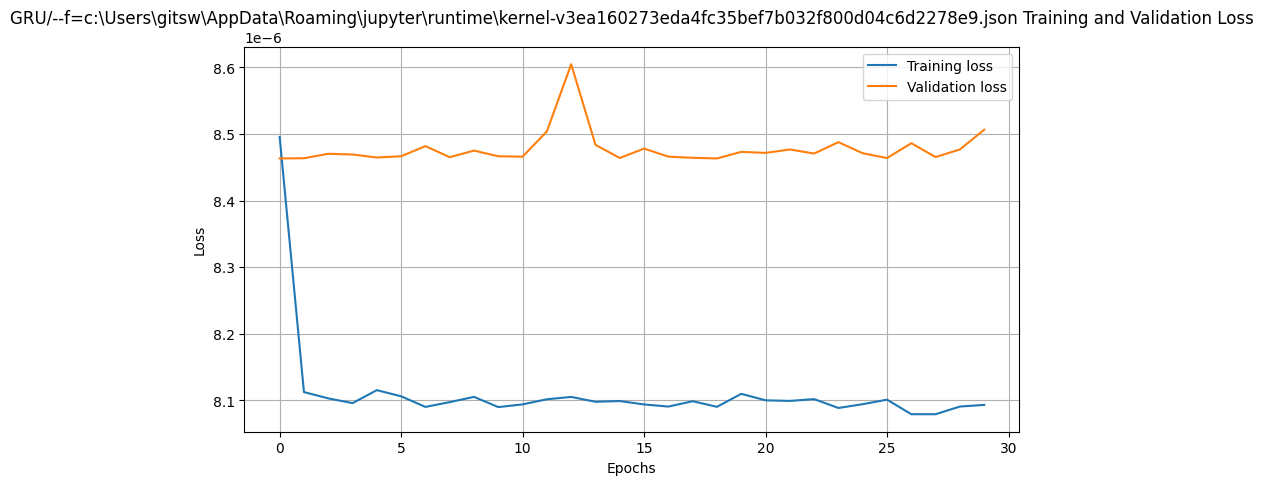

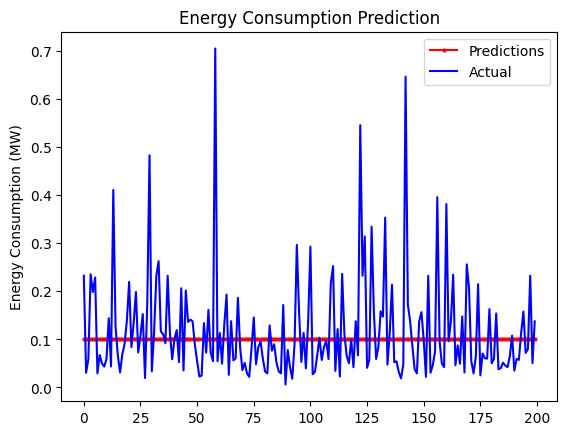

In [13]:
## GRU without k fold
#print("singleDF", sdf.describe())
train_seq, test_seq, valid_seq = divide_sequences(X, Y)
feature_len = train_seq[0].shape[2]
print("shape train::", train_seq[0].shape, train_seq[1].shape)
print("shape test::", test_seq[0].shape, test_seq[1].shape)
gru_model = GRUModel(feature_len, batch_size=1024, num_layers=20, hidden_size=128, iteration_name=it_name,cnn=True,cnn_ol=15, lr=0.001, reg=1e-6, epochs=30)
gru_model.run_model(train_seq, test_seq, valid_seq)

In [14]:
!nvidia-smi

Wed Sep 23 14:34:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.79                 Driver Version: 595.79         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4070 ...  WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   56C    P0             49W /   55W |    7694MiB /   8188MiB |      8%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [15]:
torch.cuda.is_available()

True

In [16]:
print("started kf")
train_seq, test_seq = divide_sequences_cf(X, Y)
feature_len = train_seq[0].shape[2]
print("shape train::", train_seq[0].shape, train_seq[1].shape)
print("shape test::", test_seq[0].shape, test_seq[1].shape)


started kf
shape train:: torch.Size([103475, 60, 6]) torch.Size([103475, 1])
shape test:: torch.Size([11498, 60, 6]) torch.Size([11498, 1])


Epoch 01/30 | Train Loss: 0.000008 (20.487s) | Val Loss: 0.000006 (0.810s)
Epoch 02/30 | Train Loss: 0.000005 (20.348s) | Val Loss: 0.000004 (0.847s)
Epoch 03/30 | Train Loss: 0.000004 (20.359s) | Val Loss: 0.000004 (0.810s)
Epoch 04/30 | Train Loss: 0.000004 (20.433s) | Val Loss: 0.000004 (0.892s)
Epoch 05/30 | Train Loss: 0.000004 (20.646s) | Val Loss: 0.000004 (1.016s)
Epoch 06/30 | Train Loss: 0.000004 (20.513s) | Val Loss: 0.000004 (0.946s)
Epoch 07/30 | Train Loss: 0.000004 (20.421s) | Val Loss: 0.000004 (0.807s)
Epoch 08/30 | Train Loss: 0.000004 (20.493s) | Val Loss: 0.000004 (0.838s)
Epoch 09/30 | Train Loss: 0.000004 (20.414s) | Val Loss: 0.000004 (0.843s)
Epoch 10/30 | Train Loss: 0.000004 (20.629s) | Val Loss: 0.000004 (0.833s)
Epoch 11/30 | Train Loss: 0.000004 (20.498s) | Val Loss: 0.000003 (0.832s)
Epoch 12/30 | Train Loss: 0.000003 (21.698s) | Val Loss: 0.000003 (0.812s)
Epoch 13/30 | Train Loss: 0.000003 (20.479s) | Val Loss: 0.000003 (0.869s)
Epoch 14/30 | Train Loss:

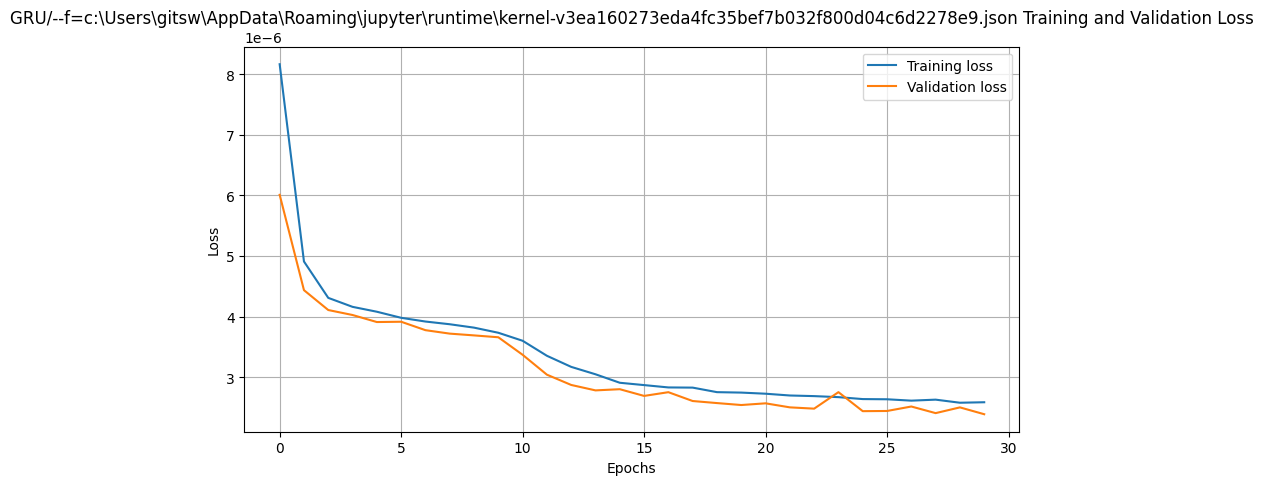

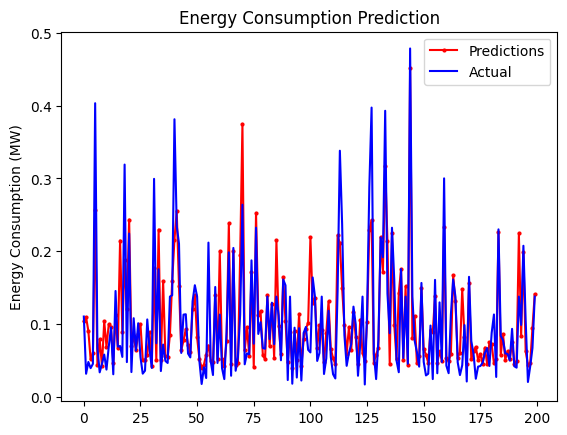

In [17]:
gru_model_kf = GRUModel(feature_len, batch_size=1024, num_layers=20, hidden_size=128, iteration_name=it_name,cnn=True,cnn_ol=10, lr=0.0001, reg=1e-6, epochs=30)

gru_model_kf.run_model(train_seq, test_seq, test_seq)

In [18]:
from torchsummary import summary
summary(gru_model.model, input_size=(60, 6))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv1d-1               [-1, 15, 60]             285
       BatchNorm1d-2               [-1, 15, 60]              30
              ReLU-3               [-1, 15, 60]               0
         MaxPool1d-4               [-1, 15, 59]               0
            Conv1d-5               [-1, 15, 59]             690
       BatchNorm1d-6               [-1, 15, 59]              30
              ReLU-7               [-1, 15, 59]               0
         MaxPool1d-8               [-1, 15, 58]               0
               GRU-9  [[-1, 58, 128], [-1, 2, 128]]               0
             ReLU-10                  [-1, 128]               0
           Linear-11                    [-1, 1]             129
Total params: 1,164
Trainable params: 1,164
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/

114973
60
6
torch.Size([114973, 60, 3])
shape train:: torch.Size([91978, 60, 3]) torch.Size([91978, 1])
shape test:: torch.Size([11498, 60, 3]) torch.Size([11498, 1])
Epoch 01/30 | Train Loss: 0.000010 (18.069s) | Val Loss: 0.000008 (0.815s)
Epoch 02/30 | Train Loss: 0.000008 (17.921s) | Val Loss: 0.000008 (0.831s)
Epoch 03/30 | Train Loss: 0.000008 (17.967s) | Val Loss: 0.000008 (0.816s)
Epoch 04/30 | Train Loss: 0.000008 (18.004s) | Val Loss: 0.000008 (0.836s)
Epoch 05/30 | Train Loss: 0.000008 (17.962s) | Val Loss: 0.000008 (0.899s)
Epoch 06/30 | Train Loss: 0.000008 (17.933s) | Val Loss: 0.000008 (0.799s)
Epoch 07/30 | Train Loss: 0.000008 (18.084s) | Val Loss: 0.000008 (0.828s)
Epoch 08/30 | Train Loss: 0.000008 (18.071s) | Val Loss: 0.000008 (0.866s)
Epoch 09/30 | Train Loss: 0.000008 (18.051s) | Val Loss: 0.000008 (0.836s)
Epoch 10/30 | Train Loss: 0.000008 (18.035s) | Val Loss: 0.000008 (0.826s)
Epoch 11/30 | Train Loss: 0.000008 (17.978s) | Val Loss: 0.000008 (0.920s)
Epoch 12

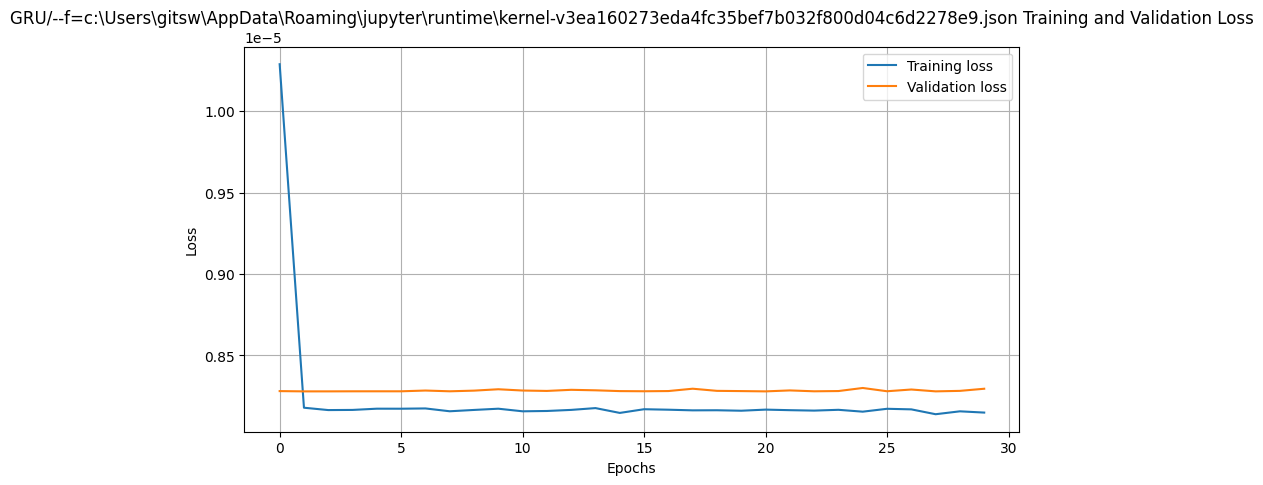

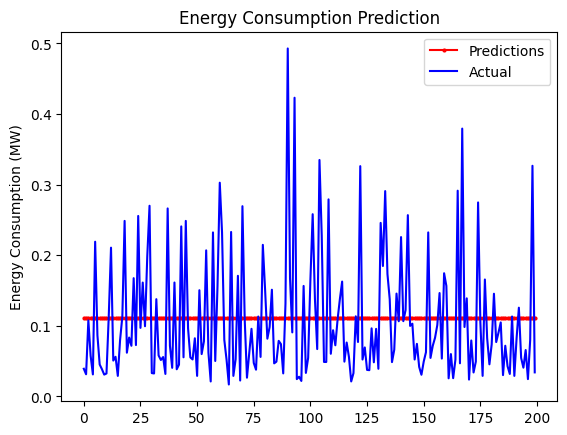

In [19]:
from sklearn.decomposition import PCA
from scipy import stats
reduced_dim = 3
print(X.size(dim=0))
print(X.size(dim=1))
print(X.size(dim=2))
X_pca = torch.zeros(size = (X.shape[0], X.shape[1], reduced_dim))
out = None
ind = 0
print(X_pca.shape)
for ind in range(X.shape[0]):
    pca = PCA(n_components = reduced_dim)
    norm = stats.zscore(X[ind], axis=1)
    pca.fit(norm)
    # print(pca.transform(X[ind, :, :]))
    X_pca[ind] = torch.from_numpy(pca.transform(norm))

train_seq, test_seq, valid_seq = divide_sequences(X_pca, Y)
gru_model = GRUModel(reduced_dim, batch_size=1024, num_layers=20, hidden_size=128, iteration_name=it_name,cnn=True,cnn_ol=15, lr=0.0001, reg=1e-6, epochs=30)
print("shape train::", train_seq[0].shape, train_seq[1].shape)
print("shape test::", test_seq[0].shape, test_seq[1].shape)
gru_model.run_model(train_seq, test_seq, valid_seq)

=== 1. Benchmarking Sequence Preprocessing: CPU vs Custom CUDA Kernel ===
shapes 15 15 torch.Size([68, 60, 6]) torch.Size([68])
[Preprocessing Benchmark] CPU: 1667.7 ms | CUDA: 29.5 ms | Speedup: 56.6x
Total Preprocessing Time (15 tracks):
  CPU (.iloc loop): 1667.70 ms
  CUDA Kernel:      29.46 ms
  Speedup Factor:   56.6x
Train shape: torch.Size([2146, 60, 6]), Test shape: torch.Size([269, 60, 6])

=== 2. Training GRU Model with Per-Epoch Latency Profiling ===
Epoch 01/15 | Train Loss: 0.000192 (0.192s) | Val Loss: 0.000149 (0.006s)
Epoch 02/15 | Train Loss: 0.000149 (0.080s) | Val Loss: 0.000125 (0.006s)
Epoch 03/15 | Train Loss: 0.000119 (0.073s) | Val Loss: 0.000103 (0.006s)
Epoch 04/15 | Train Loss: 0.000101 (0.069s) | Val Loss: 0.000091 (0.004s)
Epoch 05/15 | Train Loss: 0.000088 (0.057s) | Val Loss: 0.000084 (0.003s)
Epoch 06/15 | Train Loss: 0.000080 (0.050s) | Val Loss: 0.000089 (0.003s)
Epoch 07/15 | Train Loss: 0.000079 (0.046s) | Val Loss: 0.000084 (0.003s)
Epoch 08/15 | T

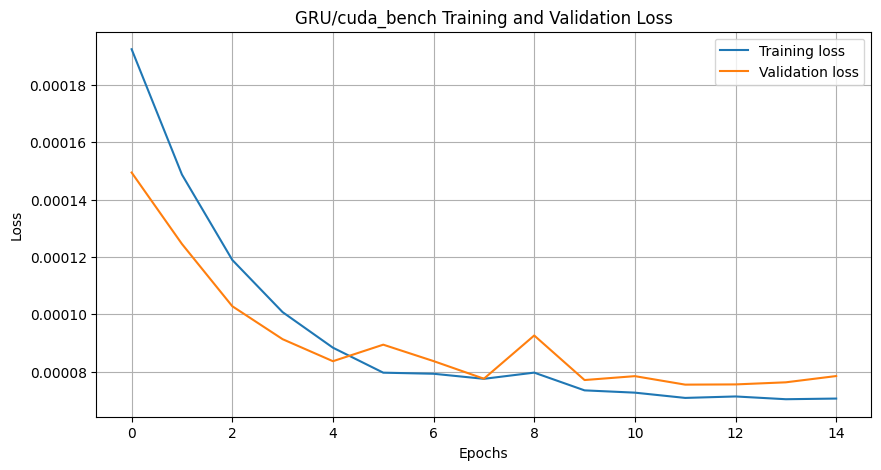

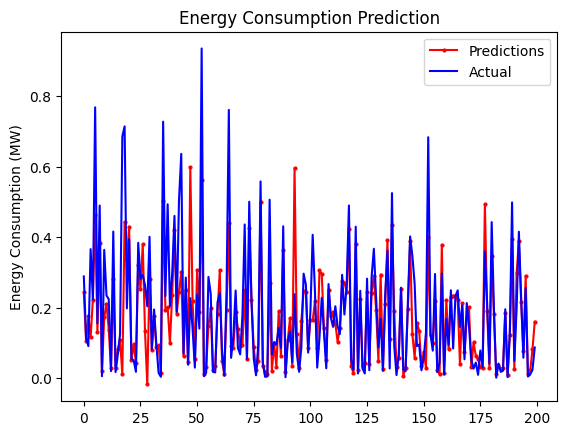


=== 3. Rendering Acceleration & Performance Dashboard ===


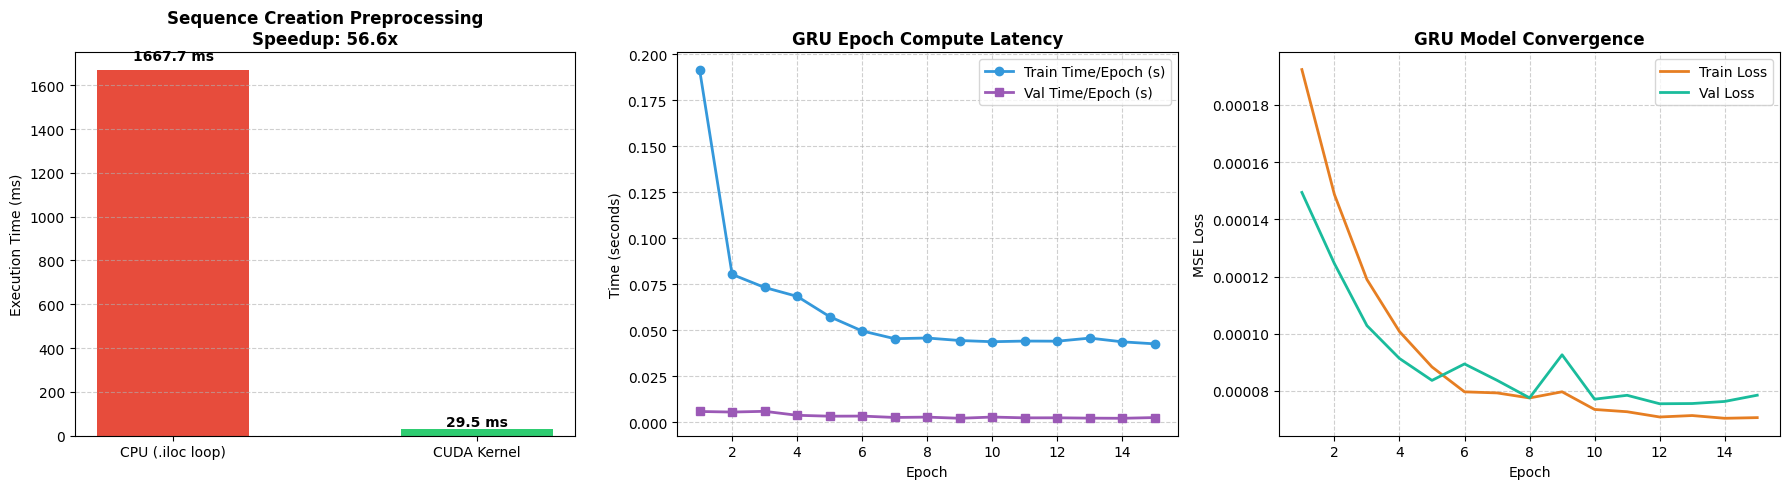

In [20]:
## CUDA vs CPU Benchmark, Model Training & Latency Dashboard
print("=== 1. Benchmarking Sequence Preprocessing: CPU vs Unaccelerated GPU vs Custom CUDA Kernel ===")
sample_ids = all_columns_present_id_list[:15]  # Benchmark on 15 tracks
X_bench, y_bench, _, cpu_prep_ms, gpu_unaccelerated_prep_ms, cuda_prep_ms = read_data(sample_ids, normalised=True, benchmark=True)
cuda_benchmark_available = _CUDA_AVAILABLE and torch.cuda.is_available()

print(f"Total Preprocessing Time (15 tracks):")
print(f"  CPU (.iloc loop): {cpu_prep_ms:.2f} ms")
if cuda_benchmark_available:
    print(f"  Unaccelerated GPU: {gpu_unaccelerated_prep_ms:.2f} ms")
    print(f"  Custom CUDA Kernel: {cuda_prep_ms:.2f} ms")
    print(f"  CPU / Unaccelerated GPU: {cpu_prep_ms / max(gpu_unaccelerated_prep_ms, 1e-4):.1f}x")
    print(f"  CPU / Custom CUDA Kernel: {cpu_prep_ms / max(cuda_prep_ms, 1e-4):.1f}x")
else:
    print("  Unaccelerated GPU: unavailable")
    print("  Custom CUDA Kernel: unavailable (CPU fallback used)")

# Split sequences
train_seq, test_seq, valid_seq = divide_sequences(X_bench, y_bench)
feature_len = train_seq[0].shape[2]
print(f"Train shape: {train_seq[0].shape}, Test shape: {test_seq[0].shape}")

print("\n=== 2. Training GRU Model with Per-Epoch Latency Profiling ===")
gru_model_timed = GRUModel(feature_len, batch_size=128, num_layers=2, hidden_size=64, iteration_name="cuda_bench", cnn=False, lr=0.001, reg=1e-6, epochs=15)
gru_model_timed.run_model(train_seq, test_seq, valid_seq)

print("\n=== 3. Rendering Acceleration & Performance Dashboard ===")
if cuda_benchmark_available:
    plot_cuda_comparison_dashboard(cpu_prep_ms, gpu_unaccelerated_prep_ms, cuda_prep_ms, gru_model_timed, model_name="GRU")
else:
    print("CUDA comparison dashboard skipped because the compiled extension is unavailable.")
